# BMTC schedule exploration
Varun D Sawalkar · Part 1 handoff
This notebook examines planned service from the cleaned community GTFS. The source revision, service day and cleaning counts come from the route manifest.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

base = Path('data/processed/gtfs') if Path('data/processed/gtfs').is_dir() else Path('processed/gtfs')
manifest = json.loads((base / 'route_manifest.json').read_text(encoding='utf-8'))
routes = pd.DataFrame(manifest['selected_routes'])
print(f"GTFS day: {manifest['service_date']} · feed version: {manifest['feed_version']}")
print(f"{manifest['routes_cleaned']:,} eligible routes · {manifest['trips_dropped_invalid_or_missing_timetable']:,} invalid trips removed")
display(routes[['rank', 'route_short_name', 'role', 'daily_trips', 'patterns', 'mean_trip_min']])
names = routes.set_index('route_id').route_short_name.to_dict()
arrivals = pd.read_csv(base / 'scheduled_arrivals.csv')
trips = pd.read_csv(base / 'scheduled_trip_times.csv')
stops = pd.read_csv(base / 'pattern_stops.csv')
headways = pd.read_csv(base / 'scheduled_headway_eda.csv')

GTFS day: 20261116 · feed version: 20261109
4,516 eligible routes · 460 invalid trips removed


,rank,route_short_name,role,daily_trips,patterns,mean_trip_min
0,1,375-D,train,434,4,33.61
1,2,378,train,384,3,83.47
2,3,401-M,held_out_transfer,353,4,56.92


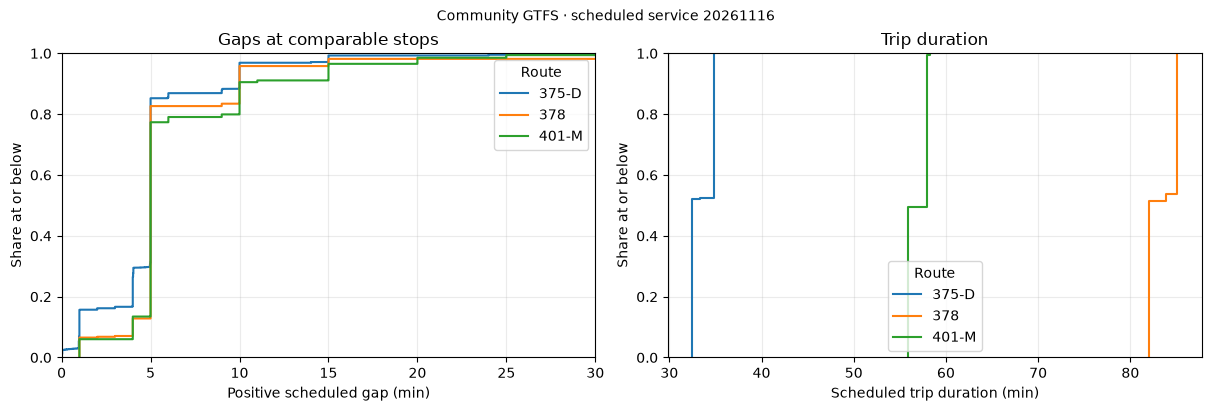

In [2]:
fig, (gap_ax, trip_ax) = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
gaps = arrivals[arrivals.planned_gap_s.gt(0)]
for route_id, name in names.items():
    minutes = gaps.loc[gaps.route_id.eq(route_id), 'planned_gap_s'] / 60
    gap_ax.ecdf(minutes, label=name)
    trip_ax.ecdf(trips.loc[trips.route_id.eq(route_id), 'trip_time_s'] / 60, label=name)
gap_ax.set(xlabel='Positive scheduled gap (min)', ylabel='Share at or below', xlim=(0, 30), title='Gaps at comparable stops')
trip_ax.set(xlabel='Scheduled trip duration (min)', ylabel='Share at or below', title='Trip duration')
for ax in (gap_ax, trip_ax):
    ax.grid(alpha=.25)
    ax.legend(title='Route')
fig.suptitle(f"Community GTFS · scheduled service {manifest['service_date']}", fontsize=10)
plt.show()

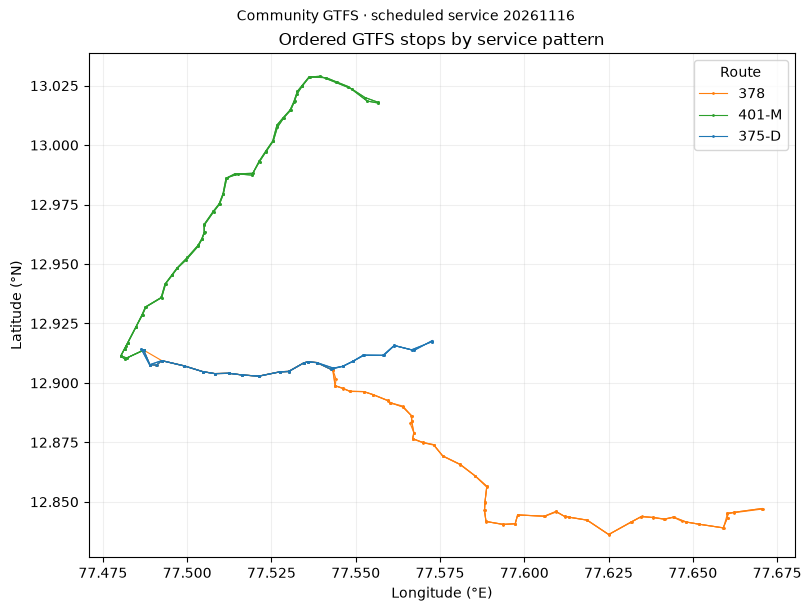

In [3]:
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
for route_id, route_stops in stops.groupby('route_id'):
    for i, (_, pattern) in enumerate(route_stops.groupby('pattern_id')):
        pattern = pattern.sort_values('stop_idx')
        ax.plot(pattern.lon, pattern.lat, marker='.', markersize=2, linewidth=.8,
                color=f"C{list(names).index(route_id)}", label=names[route_id] if i == 0 else None)
ax.set(xlabel='Longitude (°E)', ylabel='Latitude (°N)', title='Ordered GTFS stops by service pattern')
ax.grid(alpha=.2)
ax.legend(title='Route')
fig.suptitle(f"Community GTFS · scheduled service {manifest['service_date']}", fontsize=10)
plt.show()

In [4]:
training = routes.loc[routes.role.eq('train'), 'route_id']
sensitivity = headways[headways.route_id.isin(training)].set_index('route_id')
sensitivity = sensitivity[[col for col in sensitivity if col.endswith('_share')]] * 100
display(sensitivity.rename(index=names).rename(columns={
    'planned_below_0.2_share': '20% threshold',
    'planned_below_0.25_share': '25% threshold',
    'planned_below_0.3_share': '30% threshold',
}).round(2))

,20% threshold,25% threshold,30% threshold
route_id,,,
378,0.00,6.55,6.55
375-D,6.87,15.71,15.71


## Threshold decision
Each value above is the percentage of positive planned gaps below the listed fraction of the median positive gap for the same pattern and stop. Use the lower 0.20 fraction as a provisional threshold because it flags fewer planned short gaps on **both** training routes. In live labeling the denominator is the planned predecessor gap for that trip-stop, with a positive median fallback. The schedule diagnostic does not measure observed bunching. Revisit the choice with arrival observations or training simulation data before evaluating on route 401-M.

## Scheduled service by hour and pattern
Each headway below is a positive predecessor gap at the same pattern and stop. A trip can contribute at several stops. Stop spacing uses straight-line distances between adjacent scheduled stops.

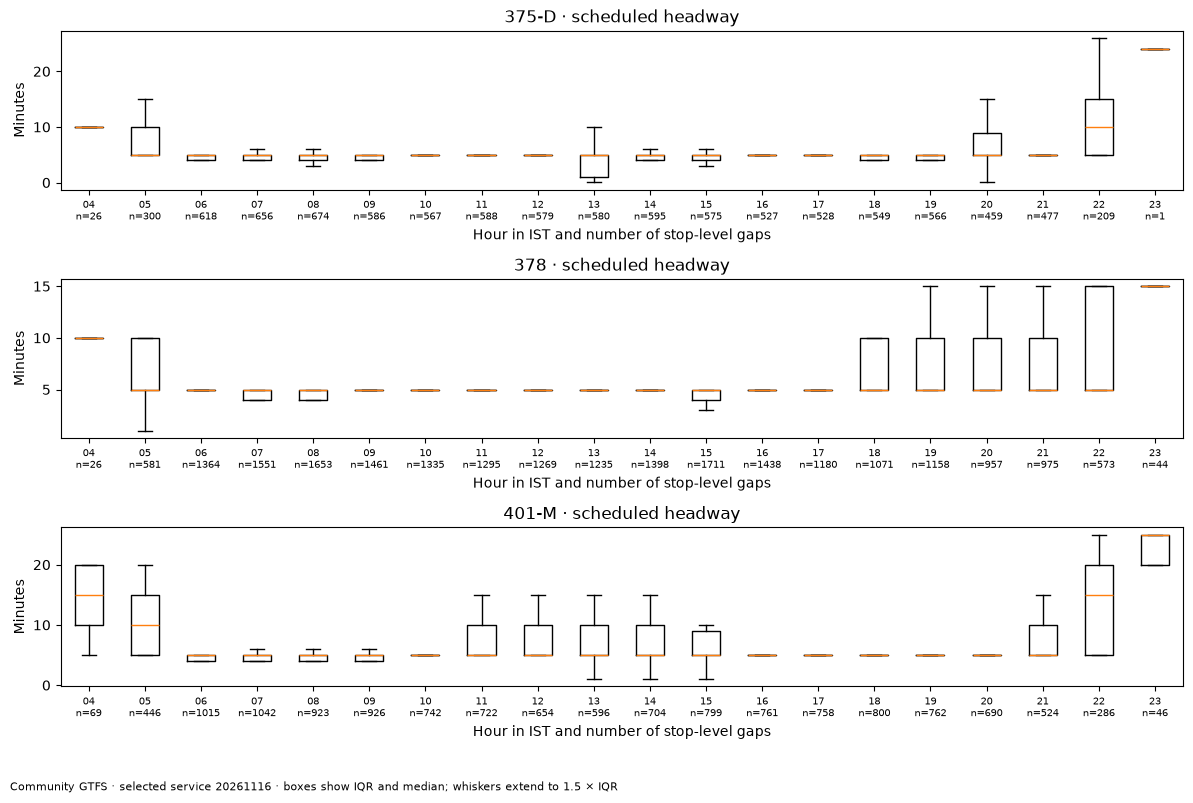

In [5]:
import sys
from matplotlib.collections import LineCollection
from IPython.display import Markdown
root = base.resolve().parents[2]
sys.path.insert(0, str(root))
from data.gtfs_clean import distance_m, read_table
from data.gps_clean import read_ways
from zipfile import ZipFile
schedule_note = f"Community GTFS · selected service {manifest['service_date']}"
def finish(fig, note):
    fig.text(.01, .005, note, fontsize=8)
    fig.tight_layout(rect=(0, .05, 1, 1))
    plt.show()

hourly = gaps.assign(hour=((gaps.arrival_s // 3600) % 24).astype(int), minutes=gaps.planned_gap_s / 60)
fig, axes = plt.subplots(len(names), 1, figsize=(12, 8), sharex=False)
for ax, (route, name) in zip(axes, names.items()):
    grouped = hourly[hourly.route_id == route].groupby('hour').minutes
    groups = list(grouped)
    ax.boxplot([v for _, v in groups], tick_labels=[f"{h:02d}\nn={len(v)}" for h,v in groups], showfliers=False)
    ax.tick_params(axis="x", labelsize=7)
    ax.set(title=f"{name} · scheduled headway", ylabel="Minutes", xlabel="Hour in IST and number of stop-level gaps")
finish(fig, schedule_note + " · boxes show IQR and median; whiskers extend to 1.5 × IQR")

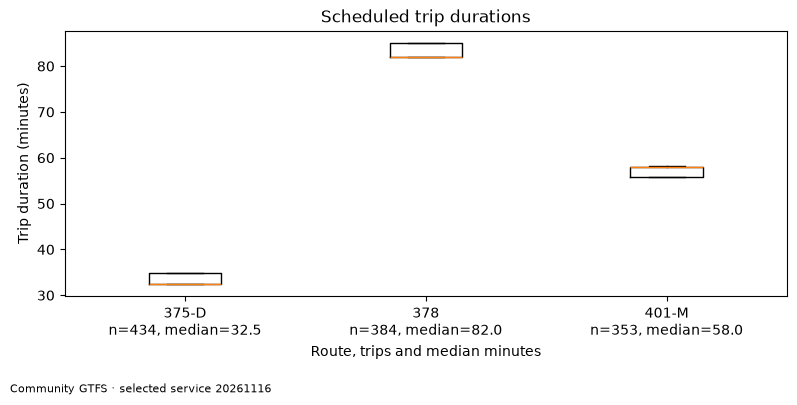

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
groups = [trips.loc[trips.route_id == r, 'trip_time_s'] / 60 for r in names]
ax.boxplot(groups, tick_labels=[f"{name}\nn={len(v)}, median={v.median():.1f}" for name,v in zip(names.values(),groups)])
ax.set(title="Scheduled trip durations", ylabel="Trip duration (minutes)", xlabel="Route, trips and median minutes")
finish(fig, schedule_note)

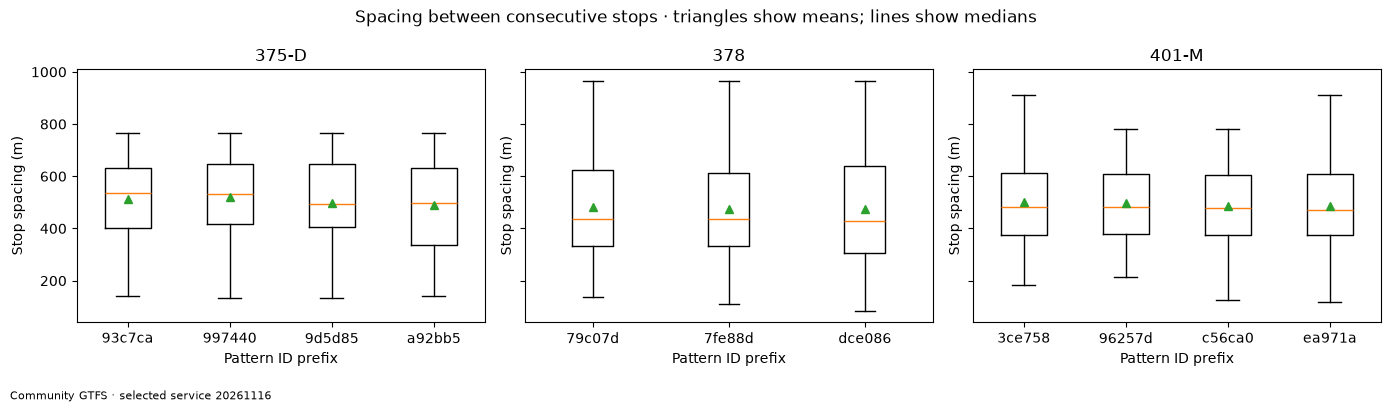

size   mean  median
route pattern_id                           
375-D 93c7ca194c1f93de    21  512.0   537.3
      99744053f89a9867    21  520.5   531.7
      9d5d8519931eadd0    22  499.3   493.1
      a92bb518345cd583    22  491.4   495.9
378   79c07dd2529d6d90    57  483.2   438.0
      7fe88da75f8c527c    57  476.3   438.0
      dce0866a41974e8f    58  474.9   429.0
401-M 3ce758ef76f8a62d    37  500.9   482.6
      96257db8556044f4    37  498.4   482.0
      c56ca06f73bc30fc    38  485.3   478.5
      ea971a61ab0c7cbf    38  487.7   472.0

In [7]:
ordered = stops.sort_values(['route_id','pattern_id','stop_idx']).copy()
prev = ordered.groupby(['route_id','pattern_id'])[['lat','lon']].shift()
ordered['meters'] = distance_m(prev.lat, prev.lon, ordered.lat, ordered.lon)
spacing = ordered.dropna(subset=['meters'])
fig, axes = plt.subplots(1, len(names), figsize=(14,4), sharey=True)
for ax, (route,name) in zip(axes,names.items()):
    groups = list(spacing[spacing.route_id == route].groupby('pattern_id').meters)
    ax.boxplot([v for _,v in groups], tick_labels=[k[:6] for k,_ in groups], showmeans=True)
    ax.set(title=name, xlabel="Pattern ID prefix", ylabel="Stop spacing (m)")
fig.suptitle("Spacing between consecutive stops · triangles show means; lines show medians")
finish(fig, schedule_note)
display(spacing.assign(route=spacing.route_id.map(names)).groupby(['route','pattern_id']).meters.agg(['size','mean','median']).round(1))

## Historical GPS coverage
Each speed sample represents two consecutive pings matched to the same OSM way. Route IDs describe geographic corridor membership. One shared road can contribute to multiple corridors.

In [8]:
gps_dir = root / 'runs/gps'
speed_file = gps_dir / 'osm_way_speeds.csv'
quality_file = gps_dir / 'gps_quality.json'
hour_file = gps_dir / 'corridor_hour_speeds.csv'
speeds = pd.read_csv(speed_file, dtype={'osm_way_id': str}) if speed_file.exists() else pd.DataFrame()
quality = json.loads(quality_file.read_text()) if quality_file.exists() else {}
verified = (speed_file.exists() and quality.get('source') == 'cni_2022'
            and quality.get('historical_data_year') == 2019 and quality.get('speed_rows') == len(speeds))
if not verified:
    print("GPS calibration not yet available")
else:
    summary = {
        'Source GPS rows': quality['raw_gps_rows'], 'Retained GPS rows':quality['valid_rows'],
        'Dropped GPS rows':quality['raw_gps_rows']-quality['valid_rows'],
        'Matched points':quality['matched_gps_points'], 'Unmatched points (includes ambiguous)':quality['unmatched_gps_points'],
        'Ambiguous points':quality['ambiguous_matches'], 'Sparse way-hour bins':quality['insufficient_way_hour_bins'],
        'OSM ways with matched points':quality['matched_osm_ways'], 'OSM ways with published speeds':speeds.osm_way_id.nunique(),
        'Historical coverage starts':quality['minimum_timestamp'], 'Historical coverage ends':quality['maximum_timestamp']}
    display(pd.Series(summary, name='Historical CNI coverage · all three corridors').to_frame())

,Historical CNI coverage · all three corridors
Source GPS rows,6014946
Retained GPS rows,6013915
Dropped GPS rows,1031
Matched points,399828
Unmatched points (includes ambiguous),5614087
Ambiguous points,206250
Sparse way-hour bins,2748
OSM ways with matched points,2690
OSM ways with published speeds,325
Historical coverage starts,2019-08-01 07:00:00+05:30


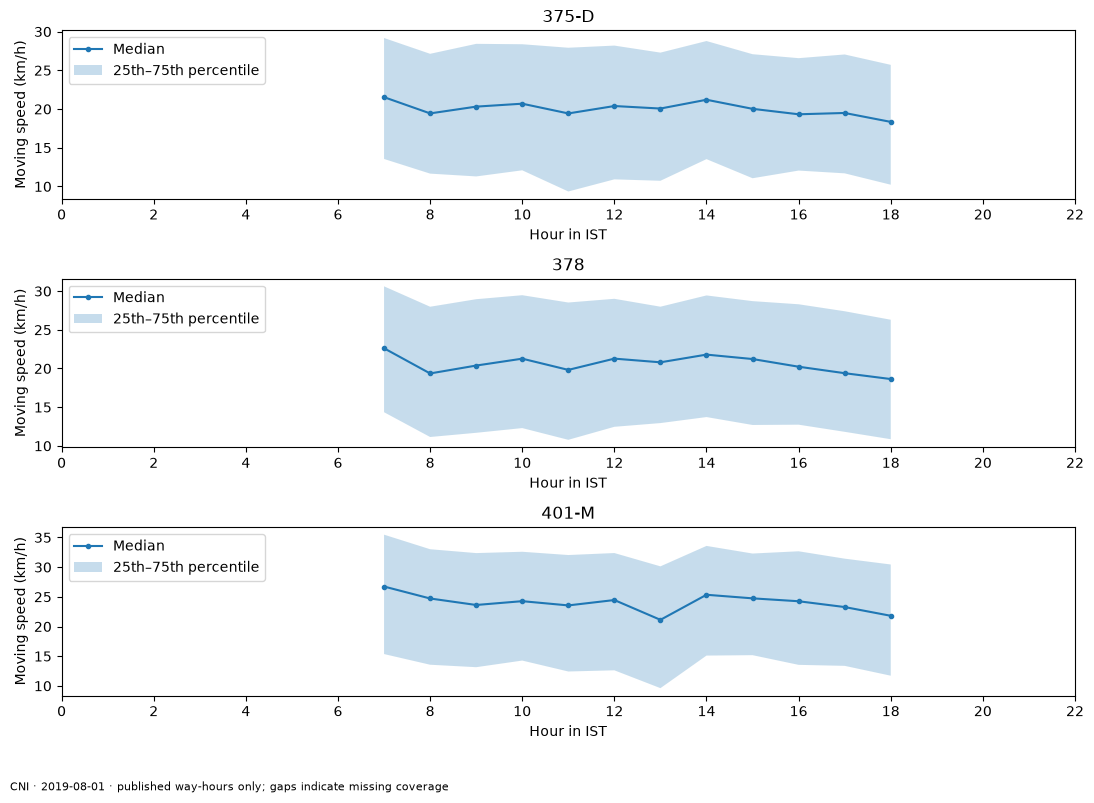

,route,hour_ist,samples,unique_buses
0,378,7.0,4137,257
1,378,8.0,4507,263
2,378,9.0,4051,247
3,378,10.0,2681,213
4,378,11.0,2731,222
5,378,12.0,2503,182
6,378,13.0,2473,179
7,378,14.0,2769,219
8,378,15.0,3069,213
9,378,16.0,3411,232


In [9]:
if verified and hour_file.exists() and not speeds.empty:
    hourly_gps = pd.read_csv(hour_file)
    fig, axes = plt.subplots(len(names),1,figsize=(11,8))
    for ax,(route,name) in zip(axes,names.items()):
        data = hourly_gps[hourly_gps.route_id == route].set_index('hour_ist').reindex(range(24))
        ax.plot(data.index,data.median_speed_kmh,marker='.',label="Median")
        ax.fill_between(data.index,data.p25_speed_kmh,data.p75_speed_kmh,alpha=.25,label="25th–75th percentile")
        ax.set(title=name, xlabel="Hour in IST", ylabel="Moving speed (km/h)", xticks=range(0,24,2))
        ax.legend()
    finish(fig, f"CNI · {quality['minimum_timestamp'][:10]} · published way-hours only; gaps indicate missing coverage")
    display(hourly_gps.assign(route=hourly_gps.route_id.map(names))[['route','hour_ist','samples','unique_buses']])
elif verified:
    print("No supported hourly GPS summaries available.")
else:
    print("GPS calibration not yet available")

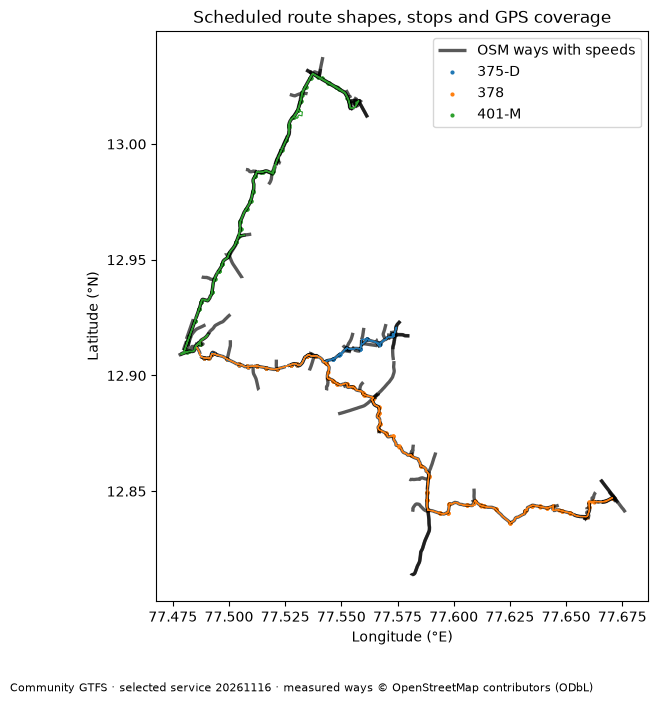

In [10]:
with ZipFile(base / 'selected_gtfs.zip') as feed:
    shapes = read_table(feed,'shapes.txt',optional=True)
    route_shapes = read_table(feed,'trips.txt')
fig,ax = plt.subplots(figsize=(8,7))
mapped = False
road_file = root / 'data/raw/corridors.osm'
if verified and road_file.exists() and not speeds.empty:
    used = set(speeds.osm_way_id)
    lines = [list(line.coords) for way,line in read_ways(road_file) if way in used]
    ax.add_collection(LineCollection(lines,colors='black',linewidths=2.4,alpha=.65,label='OSM ways with speeds'))
    mapped = bool(lines)
for i,(route,name) in enumerate(names.items()):
    route_stops = stops[stops.route_id == route]
    if not shapes.empty:
        ids = route_shapes.loc[route_shapes.route_id == route,'shape_id'].unique()
        for _,line in shapes[shapes.shape_id.isin(ids)].groupby('shape_id'):
            line = line.assign(seq=pd.to_numeric(line.shape_pt_sequence)).sort_values('seq')
            ax.plot(line.shape_pt_lon.astype(float),line.shape_pt_lat.astype(float),color=f'C{i}',lw=.8)
    ax.scatter(route_stops.lon,route_stops.lat,s=4,color=f'C{i}',label=name)
ax.set(title='Scheduled route shapes, stops and GPS coverage',xlabel='Longitude (°E)',ylabel='Latitude (°N)')
ax.set_aspect(1.03)
ax.legend()
finish(fig, schedule_note + (' · measured ways © OpenStreetMap contributors (ODbL)' if mapped else ' · GPS overlay unavailable'))

## Conclusion
375-D and 378 are the training routes. Reserve 401-M for the transfer evaluation. All three serve Kengeri, so some geographic overlap is expected. The GPS panels describe historical moving speeds on covered roads. Scheduled headways and trip times describe the selected GTFS service day.

In [11]:
if verified:
    display(Markdown(f"**Available measurements.** {quality['matched_same_way_pairs']:,} same-way moving pairs yielded "
                     f"{len(speeds):,} supported way-hours across {speeds.osm_way_id.nunique():,} OSM ways. "
                     "The hourly table counts distinct buses within each corridor and hour."))
else:
    display(Markdown("**GPS calibration not yet available.** The schedule analyses above are available."))

**Available measurements.** 88,350 same-way moving pairs yielded 2,198 supported way-hours across 325 OSM ways. The hourly table counts distinct buses within each corridor and hour.